# Bike Sharing Case: Do We Need to Buy More Bikes?

The Streamlit application is maintained separately in the repository root as `app.py`. Do not generate or overwrite that file from this notebook.

## Question
Riders can't find bikes when they need them, yet bikes sit idle around the city. Should the company buy more?

## Short answer
Not yet. Demand is concentrated in commute hours and the rest of the day is quieter. First forecast demand and test placing bikes before the rush; consider buying only if shortages remain. The supplied data has citywide totals only, so it cannot identify station-level shortages.

## Data
Capital Bikeshare, Washington D.C., 2011–2012. Source files: `day.csv` and `hour.csv`.

## Data quality
The raw files contain 731 daily rows and 17,379 hourly rows, with no nulls or duplicates in the supplied columns. The count identity `cnt = casual + registered` holds. There are 165 missing hourly timestamps. These are flagged and filled with zero rentals for analysis; this is an assumption, especially for daytime gaps on storm days. The low-demand day on 29 October 2012 (Hurricane Sandy) is retained as a real event.

## Main findings
1. Working days have morning and evening commute peaks; weekends have a gentler midday pattern.
2. The four commute hours (07:00–08:00 and 17:00–18:00) account for a median 39.3% of working-day rentals versus 17.0% on non-working days. The notebook tests this with a one-sided Mann–Whitney U test after excluding days with filled commute-hour observations.
3. Weather, season and year are associated with demand. The season labels are corrected using the month cross-tab: code 1 winter, 2 spring, 3 summer, 4 fall.

## Forecast model
A HistGradientBoostingRegressor predicts hourly rental counts using calendar, weather, trend and 24-hour/168-hour lagged demand. `casual` and `registered` are excluded from predictors to avoid target leakage. Training ends before 15 October 2012; the test period is 15 October–31 December 2012. The notebook reports MAE 45.5, RMSE 75.0 and R² 0.849 versus a same-hour-last-week baseline of MAE 77.2, RMSE 132.1 and R² 0.533.

A separate quantile model and peak/off-peak calibration produce an upper-demand planning estimate. Its reported coverage is empirical and potentially optimistic because calibration choices were made after examining the test period.

## Bikes in use and limitations
Hourly rentals are not simultaneous bikes. Concurrent bikes in use are approximated as hourly rentals multiplied by assumed trip duration. This is not total fleet size. The data has no station inventory, trip origins/destinations, actual trip durations, failed-rental logs or total fleet size. The test window is October–December, and exceptional events such as Hurricane Sandy are difficult to predict. Actual weather is used instead of a weather forecast.

## Prototype and recommendation
The separate Streamlit app lets an operations manager ask a natural-language demand question. Gemini extracts the date, hour, weather and trip-duration assumptions; the saved ML models supply the numerical estimates. Do not buy bikes immediately. Test forecast-driven redistribution before 07:00 and 16:00 in a 4–6 week controlled pilot, using failed-rental rate during peak hours as the primary outcome. Buy only if shortages persist after rebalancing.


In [5]:
# Load source data from the repository root (or /content in Colab)
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd()
if not (DATA_DIR / 'day.csv').exists():
    DATA_DIR = Path('/content')
day = pd.read_csv(DATA_DIR / 'day.csv')
hour = pd.read_csv(DATA_DIR / 'hour.csv')
day['dteday'] = pd.to_datetime(day['dteday'], format='mixed', dayfirst=True)
hour['dteday'] = pd.to_datetime(hour['dteday'], format='mixed', dayfirst=True)


In [8]:
#Quality Check
print(day.shape, hour.shape)
print(day.isna().sum().sum(), hour.isna().sum().sum())
print(day.duplicated().sum(), hour.duplicated().sum())
print((hour.cnt != hour.casual + hour.registered).sum())
print(day.dteday.min(), day.dteday.max())

(731, 16) (17379, 17)
0 0
0 0
0
2011-01-01 00:00:00 2012-12-31 00:00:00


In [9]:
#missing hour
ts = hour.dteday + pd.to_timedelta(hour.hr, unit="h")
missing = pd.date_range(ts.min(), ts.max(), freq="h").difference(ts)
print(len(missing))
print(pd.Series(missing.hour).value_counts().sort_index())

165
0      5
1      7
2     16
3     34
4     34
5     14
6      6
7      4
8      4
9      4
10     4
11     4
12     3
13     2
14     2
15     2
16     1
17     1
18     3
19     3
20     3
21     3
22     3
23     3
Name: count, dtype: int64


In [11]:
#Which days have the daytime gaps
late = missing[missing.hour >= 6]
print(pd.Series(late.date).value_counts())

2012-10-29    18
2011-01-27    10
2012-10-30     7
2011-01-18     6
2011-08-27     6
2011-01-26     6
2011-01-30     1
2011-08-28     1
Name: count, dtype: int64


In [13]:
#Hourly vs. daily, lowest days
diff = hour.groupby("dteday").cnt.sum() - day.set_index("dteday").cnt
print((diff != 0).sum())
print(day.nsmallest(3, "cnt")[["dteday", "cnt", "weathersit"]])

0
        dteday  cnt  weathersit
667 2012-10-29   22           3
26  2011-01-27  431           1
725 2012-12-26  441           3


In [14]:
#Fill the missing hours
hour["ts"] = hour.dteday + pd.to_timedelta(hour.hr, unit="h")
full = pd.date_range(hour.ts.min(), hour.ts.max(), freq="h")
h = hour.set_index("ts").reindex(full)

h["filled"] = h.cnt.isna()
h[["casual", "registered", "cnt"]] = h[["casual", "registered", "cnt"]].fillna(0)
w = ["weathersit", "temp", "atemp", "hum", "windspeed"]
h[w] = h[w].ffill()

h["dteday"] = h.index.normalize()
h["hr"] = h.index.hour
cal = day.set_index("dteday")[["season", "yr", "mnth", "holiday", "weekday", "workingday"]]
h[cal.columns] = cal.reindex(h.dteday).values

print(len(h), h.filled.sum(), h.cnt.sum() == hour.cnt.sum())

17544 165 True


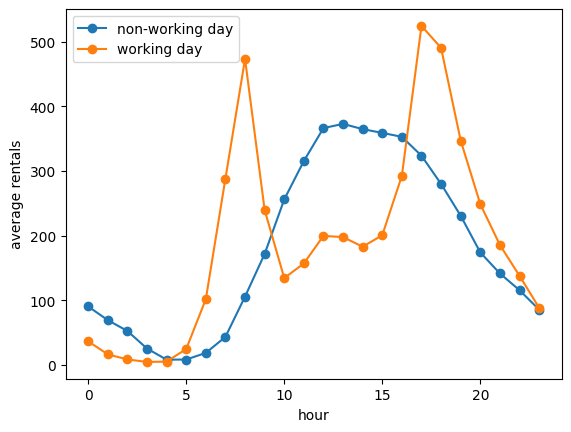

hr
17    524.0
18    490.0
8     473.0
Name: cnt, dtype: float64


In [15]:
#exploration chart
import matplotlib.pyplot as plt

h.groupby(["workingday", "hr"]).cnt.mean().unstack(0).plot(marker="o")
plt.legend(["non-working day", "working day"])
plt.xlabel("hour"); plt.ylabel("average rentals"); plt.show()

print(h[h.workingday == 1].groupby("hr").cnt.mean().nlargest(3).round())

In [16]:
#Season labels
print(pd.crosstab(day.season, day.mnth))
print(day.groupby("season").cnt.mean().round())


mnth    1   2   3   4   5   6   7   8   9   10  11  12
season                                                
1       62  57  40   0   0   0   0   0   0   0   0  22
2        0   0  22  60  62  40   0   0   0   0   0   0
3        0   0   0   0   0  20  62  62  44   0   0   0
4        0   0   0   0   0   0   0   0  16  62  60  40
season
1    2604.0
2    4992.0
3    5644.0
4    4728.0
Name: cnt, dtype: float64


In [18]:
# Headline numbers: daily demand, user split, yearly growth, weather effect, peak hour
print(round(day.cnt.mean()), day.cnt.max(), day.cnt.min())
print((day[["casual", "registered"]].sum() / day.cnt.sum()).round(3))
print(day.groupby("yr").cnt.mean().round())
print(day.groupby("weathersit").cnt.mean().round())

p = h.groupby("hr").cnt.mean()
print(p.idxmax(), round(p.max(), 1), round(p[17] / p[4]))

4504 8714 22
casual        0.188
registered    0.812
dtype: float64
yr
0    3406.0
1    5600.0
Name: cnt, dtype: float64
weathersit
1    4877.0
2    4036.0
3    1803.0
Name: cnt, dtype: float64
17 460.8 76


In [20]:
# Replace the misleading season codes with real season names
names = {1: "winter", 2: "spring", 3: "summer", 4: "fall"}
day["season_name"] = day.season.map(names)
h["season_name"] = h.season.map(names)

In [21]:
# Share of each day's rentals in commute hours (7-8 AM, 5-6 PM)
peak = [7, 8, 17, 18]
d = h.groupby("dteday").agg(total=("cnt", "sum"), wd=("workingday", "first"))
d["share"] = h[h.hr.isin(peak)].groupby("dteday").cnt.sum() / d.total

bad = h[h.hr.isin(peak) & h.filled].dteday.unique()
d = d.drop(bad)
print(len(bad), "days dropped")
print(d.groupby("wd").share.median().round(3))

6 days dropped
wd
0    0.170
1    0.393
Name: share, dtype: float64


In [22]:
from scipy.stats import mannwhitneyu
import numpy as np

a = d[d.wd == 1].share
b = d[d.wd == 0].share
print("p-value:", mannwhitneyu(a, b, alternative="greater").pvalue)

gap = a.median() - b.median()
boot = [a.sample(len(a), replace=True).median() - b.sample(len(b), replace=True).median()
        for _ in range(2000)]
print("median gap:", round(gap, 3), "95% CI:", np.percentile(boot, [2.5, 97.5]).round(3))

wk = h[h.workingday == 1].cnt
print("working-day mean / p95 demand:", round(wk.mean() / wk.quantile(0.95), 2))

p-value: 1.6822520342222913e-102
median gap: 0.223 95% CI: [0.218 0.227]
working-day mean / p95 demand: 0.33


In [23]:
#Features
# Model inputs. casual/registered are left out: they add up to the target
f = h.copy()
f["temp_c"] = f.temp * 41
f["atemp_c"] = f.atemp * 50
f["hum_pct"] = f.hum * 100
f["wind"] = f.windspeed * 67
f["is_peak"] = ((f.workingday == 1) & f.hr.isin([7, 8, 17, 18])).astype(int)
f["lag_24"] = f.cnt.shift(24)
f["lag_168"] = f.cnt.shift(168)
f["t"] = (f.index - f.index[0]).days
f = f.dropna(subset=["lag_168"])

cols = ["hr", "weekday", "workingday", "holiday", "mnth", "weathersit",
        "temp_c", "atemp_c", "hum_pct", "wind", "is_peak", "lag_24", "lag_168", "t"]
print(f.shape, f[cols].isna().sum().sum())

(17376, 27) 0


In [24]:
#Split and baseline
# Train before 15 Oct 2012, test on the rest (includes Hurricane Sandy)
from sklearn.metrics import mean_absolute_error as mae

train = f[f.index < "2012-10-15"]
test = f[f.index >= "2012-10-15"]

print(len(train), len(test))
print("baseline (same hour last week) MAE:", round(mae(test.cnt, test.lag_168), 1))

15504 1872
baseline (same hour last week) MAE: 77.2


In [25]:
# Gradient boosting vs. the same-hour-last-week baseline, with and without Sandy
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

model = HistGradientBoostingRegressor(random_state=0)
model.fit(train[cols], train.cnt)
test = test.assign(pred=model.predict(test[cols]).clip(0))

def score(df, col):
    return round(mae(df.cnt, df[col]), 1), round(mean_squared_error(df.cnt, df[col]) ** 0.5, 1), round(r2_score(df.cnt, df[col]), 3)

no_sandy = test[~test.dteday.between("2012-10-29", "2012-10-30")]
print("MAE, RMSE, R2")
print("model, all:     ", score(test, "pred"))
print("model, no Sandy:", score(no_sandy, "pred"))
print("baseline, all:     ", score(test, "lag_168"))
print("baseline, no Sandy:", score(no_sandy, "lag_168"))

MAE, RMSE, R2
model, all:      (45.5, 75.0, 0.849)
model, no Sandy: (43.6, 70.6, 0.867)
baseline, all:      (77.2, 132.1, 0.533)
baseline, no Sandy: (71.8, 119.6, 0.617)


In [26]:
# Quantile models estimate a high-demand level (p90, p95) for fleet sizing
for q, name in [(0.9, "p90"), (0.95, "p95")]:
    m = HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=0)
    m.fit(train[cols], train.cnt)
    test[name] = m.predict(test[cols]).clip(0)
    print(name, "covers", round((test.cnt <= test[name]).mean(), 3), "of test hours")

p90 covers 0.843 of test hours
p95 covers 0.92 of test hours


In [27]:
# Fit on earlier data, measure the miss on a later window, shift the interval by it
fit = train[train.index < "2012-08-15"]
cal = train[train.index >= "2012-08-15"]

for q, name in [(0.9, "p90"), (0.95, "p95")]:
    m = HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=0)
    m.fit(fit[cols], fit.cnt)
    shift = (cal.cnt - m.predict(cal[cols])).quantile(q)
    test[name + "_adj"] = (m.predict(test[cols]) + shift).clip(0)
    print(name, "shift:", round(shift), "| test coverage:", round((test.cnt <= test[name + "_adj"]).mean(), 3))

print(test.groupby("is_peak").apply(lambda d: (d.cnt <= d.p95).mean()).round(3))

p90 shift: 27 | test coverage: 0.918
p95 shift: 41 | test coverage: 0.959
is_peak
0    0.922
1    0.906
dtype: float64


/tmp/ipykernel_3925/3972609563.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(test.groupby("is_peak").apply(lambda d: (d.cnt <= d.p95).mean()).round(3))


In [28]:
# Bikes in use at once ~ rentals per hour x trip length (hours). Trip length is an assumption
print((test.cnt <= test.p95_adj).groupby(test.is_peak).mean().round(3))

peak = test.groupby("dteday").p95_adj.max()
rows = []
for mins in [15, 30, 60]:
    d = mins / 60
    rows.append([mins, round(test.cnt.mean() * d), round(peak.median() * d), round(peak.max() * d)])

out = pd.DataFrame(rows, columns=["trip_min", "avg_in_use", "typical_peak_need", "busiest_day_need"])
out["avg_vs_peak"] = (out.avg_in_use / out.typical_peak_need).round(2)
print(out)

is_peak
0    0.972
1    0.858
dtype: float64
   trip_min  avg_in_use  typical_peak_need  busiest_day_need  avg_vs_peak
0        15          51                181               234         0.28
1        30         102                362               469         0.28
2        60         204                723               937         0.28


In [29]:
# Separate calibration shift for peak and off-peak hours
for q, name in [(0.9, "p90"), (0.95, "p95")]:
    m = HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=0)
    m.fit(fit[cols], fit.cnt)
    res = cal.cnt - m.predict(cal[cols])
    shift = test.is_peak.map({1: res[cal.is_peak == 1].quantile(q), 0: res[cal.is_peak == 0].quantile(q)})
    test[name + "_adj2"] = (m.predict(test[cols]) + shift).clip(0)
    ok = test.cnt <= test[name + "_adj2"]
    print(name, "peak:", round(ok[test.is_peak == 1].mean(), 3), "| off-peak:", round(ok[test.is_peak == 0].mean(), 3))


p90 peak: 0.925 | off-peak: 0.89
p95 peak: 0.962 | off-peak: 0.961


In [35]:

# Bikes needed, using the p95 calibrated separately for peak and off-peak
day_peak = test.groupby("dteday").p95_adj2.max()
rows = []
for mins in [15, 30, 60]:
    hrs = mins / 60
    rows.append([mins, round(test.cnt.mean() * hrs), round(day_peak.median() * hrs), round(day_peak.max() * hrs)])

out = pd.DataFrame(rows, columns=["trip_min", "avg_in_use", "typical_peak_need", "busiest_day_need"])
out["avg_vs_peak"] = (out.avg_in_use / out.typical_peak_need).round(2)
print(out)


   trip_min  avg_in_use  typical_peak_need  busiest_day_need  avg_vs_peak
0        15          51                193               248         0.26
1        30         102                386               495         0.26
2        60         204                771               990         0.26


In [31]:
import joblib

q95 = HistGradientBoostingRegressor(loss="quantile", quantile=0.95, random_state=0).fit(fit[cols], fit.cnt)
res = cal.cnt - q95.predict(cal[cols])
shifts = {1: res[cal.is_peak == 1].quantile(0.95), 0: res[cal.is_peak == 0].quantile(0.95)}

joblib.dump({"median": model, "p95": q95, "shifts": shifts, "cols": cols}, "bike_model.joblib")
f[f.index >= "2012-10-15"][cols + ["cnt"]].to_csv("replay.csv")
print(shifts)

{1: np.float64(93.81140374998064), 0: np.float64(23.768025865039725)}


In [32]:
# The deployment application is maintained in the repository-level app.py.
# Keep the application separate from notebook execution to avoid overwriting it.
from pathlib import Path
app_file = Path('app.py')
print(f'Use {app_file.resolve()} for the Streamlit app.' if app_file.exists() else 'The Streamlit app is a separate repository file: app.py.')


Writing app.py


In [34]:
# Check the saved model, then one rain what-if
import joblib, pandas as pd
pack = joblib.load("bike_model.joblib")
data = pd.read_csv("replay.csv", index_col=0, parse_dates=True)
X = data[pack["cols"]]

high = pack["p95"].predict(X) + data.is_peak.map(pack["shifts"])
print((data.cnt <= high).groupby(data.is_peak).mean().round(3))

d20 = data.loc["2012-12-20"]
rain = d20.assign(weathersit=3)
out = pd.DataFrame({"actual": d20.cnt,
                    "expected": pack["median"].predict(d20[pack["cols"]]).round(),
                    "if_rain": pack["median"].predict(rain[pack["cols"]]).round()})
print(out[out.index.hour.isin([8, 17])])

is_peak
0    0.961
1    0.962
dtype: float64
                     actual  expected  if_rain
2012-12-20 08:00:00   599.0     712.0    507.0
2012-12-20 17:00:00   475.0     586.0    487.0
